### SUPPORT VECTOR MACHINE

It converts the input space(2D) into high dimensional space. it will be able to differentiate between the classes properly. • datapoints/vectors are converted into high dimensional space, a hyperplane is fit . • decision boundaries are drawn parallel to the hyperplanes. Each decision boundary must pass through 1 or more vectors of that class. • margin refers to the distance between both the decision boundaries. • distance from hyperplane to each decision boundary line is calculated. • the hyperplane that gives maximum distance, is considered as the final hyperplane.

**how are input space 2D converted into high dimensional space: kernel**

### Data Gathering/Data Ingestion

In [1]:
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
path = r"https://raw.githubusercontent.com/kavaderohan2005-netizen/Datasets/refs/heads/main/drug200.csv"
import pandas as pd
df = pd.read_csv(path)
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


### Y : Drug

In [3]:
df['Drug'].value_counts()

Drug
DrugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64

In [4]:
len(df)

200

In [5]:
((df['Drug'].value_counts())/len(df))*100

Drug
DrugY    45.5
drugX    27.0
drugA    11.5
drugC     8.0
drugB     8.0
Name: count, dtype: float64

<Axes: xlabel='Drug'>

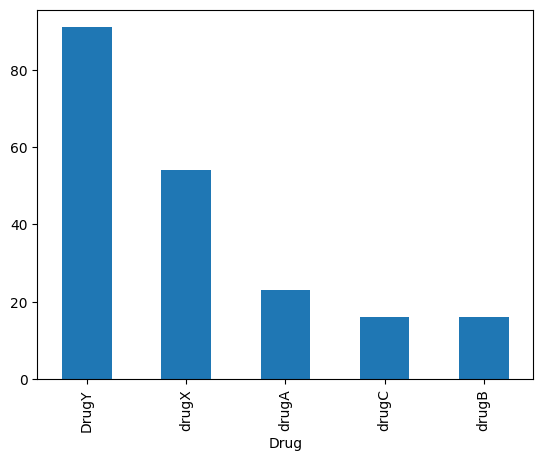

In [6]:
df['Drug'].value_counts().plot(kind='bar')

### The data appears to be imbalanced. We have to apply resampling technique

In [7]:
len(df)

200

### Separate X and Y features

    Y :Drug

In [8]:
X = df.drop(columns=['Drug'])
Y = df[['Drug']]
X.head()

,Age,Sex,BP,Cholesterol,Na_to_K
0,23,F,HIGH,HIGH,25.355
1,47,M,LOW,HIGH,13.093
2,47,M,LOW,HIGH,10.114
3,28,F,NORMAL,HIGH,7.798
4,61,F,LOW,HIGH,18.043


In [9]:
Y.head()

,Drug
0,DrugY
1,drugC
2,drugC
3,drugX
4,DrugY


### Split the data into training and testing

    training: 80% 
    testing: 20%

In [11]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(X,Y,train_size=0.8,random_state=21)

### Data Preprocessing and Data Cleaning

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

cat = list(X.select_dtypes(include='object').columns) 
con = list(X.select_dtypes(include='number').columns)

num_pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    MinMaxScaler()
)

cat_pipe = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore',sparse_output=False)
)

pre = ColumnTransformer([(
    "cat",cat_pipe,cat
),
("con",num_pipe,con)]).set_output(transform='pandas')
pre

,transformers,"[('cat', ...), ('con', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None


In [16]:
pre.fit(xtrain)

,transformers,"[('cat', ...), ('con', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None


In [17]:
xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

In [18]:
from imblearn.over_sampling import SMOTE

In [19]:
smote = SMOTE()
x_sampl,y_sampl = smote.fit_resample(xtrain_pre,ytrain)

In [20]:
y_sampl['Drug'].value_counts()

Drug
drugA    70
drugX    70
drugB    70
drugC    70
DrugY    70
Name: count, dtype: int64

### Model Building: SVM

In [22]:
from sklearn.svm import SVC

model = SVC()
model.fit(x_sampl,y_sampl)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [23]:
model.score(x_sampl,y_sampl)

0.8914285714285715

In [24]:
model.score(xtest_pre,ytest)

0.65

### THis model is resulting in overfitting scenario

In [25]:
model2 = SVC(kernel='poly')
model2.fit(x_sampl,y_sampl)

,C,1.0
,kernel,'poly'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [26]:
model2.score(x_sampl,y_sampl)

0.9657142857142857

In [27]:
model.score(xtest_pre,ytest)

0.65

In [28]:
model3 = SVC(kernel='rbf')
model3.fit(x_sampl,y_sampl)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [29]:
model3.score(x_sampl,y_sampl)

0.8914285714285715

In [30]:
model3.score(xtest_pre,ytest)

0.65

### THis model is ending up in overfitting situation irrespective of kernel type. We will not finalise this model